# 02 펌프 센서별 원본 시계열 그래프

1. 원본 센서 데이터와 시각 확인
2. 원본값과 결측 구간을 그리는 함수 준비
3. 센서별 PNG 저장 및 예시 확인

기본 입력은 `data/sensor.csv`입니다. Python 커널에 `pandas`, `numpy`, `matplotlib`가 필요합니다. 실행하면 `figures/sensor_missingness/`의 같은 이름 PNG를 갱신합니다.

## 1. 원본 파일과 시간축 확인

`sensor_00`부터 `sensor_51`까지 원본 센서 전체를 사용합니다. 각 기록의 시각을 확인한 후 1분 단위 시간축에 맞춥니다.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 저장소 최상위나 notebooks/에서 실행할 수 있도록 공통 데이터 경로를 찾습니다.
cwd = Path.cwd()
project_root = next(
    (path for path in (cwd, *cwd.parents) if (path / "src/pump_missingness_audit.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소나 notebooks 폴더에서 커널을 실행하세요.")

sys.path.insert(0, str(project_root))
from src.plot_style import save_png, use_portable_style
from src.pump_missingness_audit import default_source, read_sensor_data

# 모든 OS에서 같은 글꼴과 같은 PNG가 나오도록 설정합니다.
use_portable_style()

source = default_source()
raw = read_sensor_data(source)
sensor_columns = sorted(column for column in raw.columns if column.startswith("sensor_"))
print(f"입력: {source.relative_to(project_root).as_posix()} · {len(raw):,}행 · 센서 {len(sensor_columns)}개")

raw["timestamp"] = pd.to_datetime(raw["timestamp"], errors="raise")
if raw["timestamp"].isna().any() or raw["timestamp"].duplicated().any():
    raise ValueError("비어 있거나 중복된 시각을 확인하세요.")
trace_data = raw.set_index("timestamp").sort_index()
if not trace_data.index.equals(trace_data.index.floor("min")):
    raise ValueError("timestamp는 분 단위여야 합니다.")
trace_data = trace_data[sensor_columns].asfreq("min")
print(f"기간: {trace_data.index[0]} ~ {trace_data.index[-1]}")

입력: data/sensor.csv · 220,320행 · 센서 52개
기간: 2018-04-01 00:00:00 ~ 2018-08-31 23:59:00


## 2. 센서값과 결측 구간 그리기

측정값은 파란 선으로 그립니다. 결측값은 원본 공백 상태를 유지해서 선이 끊기고, 아래 주황색 줄에 결측 구간을 표시합니다. 2시간 이상인 연속 결측은 본 그래프에도 음영으로 표시합니다.

In [ ]:
line_color = "#245b89"
missing_color = "#b54828"
grid_color = "#e5eaf0"
label_color = "#28384a"

def save_sensor_trace(series, target):
    """한 센서의 원본 1분 시계열과 결측 구간을 PNG로 저장합니다."""
    values = series.to_numpy(dtype=float)
    timestamps = series.index
    minutes = np.arange(len(series))
    missing = np.isnan(values)
    # 결측 여부가 바뀌는 경계로 연속 결측의 시작과 끝을 구합니다.
    edges = np.flatnonzero(np.diff(np.r_[False, missing, False]))
    starts, ends = edges[::2], edges[1::2]
    lengths = ends - starts
    missing_count = int(missing.sum())
    longest = int(lengths.max()) if lengths.size else 0
    ticks = pd.date_range(timestamps[0].normalize(), timestamps[-1], freq="MS")
    ticks = ticks[(ticks > timestamps[0]) & (ticks < timestamps[-1].normalize())]
    ticks = pd.DatetimeIndex([timestamps[0], *ticks, timestamps[-1]]).unique()
    tick_positions = (ticks - timestamps[0]) / pd.Timedelta(minutes=1)

    fig, (trace, availability) = plt.subplots(
        2, 1, figsize=(12, 4.15), sharex=True,
        gridspec_kw={"height_ratios": [10, 1]},
    )
    fig.subplots_adjust(left=.09, right=.98, bottom=.15, top=.78, hspace=.09)
    fig.text(.09, .925, series.name, fontsize=20, fontweight="bold", color="#1d2b39")
    fig.text(
        .09, .85,
        f"Raw 1-minute readings  |  {timestamps[0]:%Y-%m-%d} to {timestamps[-1]:%Y-%m-%d}"
        f"  |  Missing {missing_count:,} / {len(series):,} min ({100 * missing_count / len(series):.3f}%)"
        f"  |  Longest gap {longest:,} min",
        fontsize=10, color=label_color,
    )
    trace.plot(minutes, values, color=line_color, linewidth=.7)
    for start, end, duration in zip(starts, ends, lengths):
        if duration >= 120:
            trace.axvspan(start - .5, end - .5, color=missing_color, alpha=.15, linewidth=0)
    trace.set_ylabel("Sensor reading")
    trace.grid(True, color=grid_color, linewidth=.7)
    trace.set_axisbelow(True)
    if missing.all():
        trace.set_yticks([])
        trace.text(.5, .5, "No readings recorded", transform=trace.transAxes,
                   ha="center", va="center", fontsize=15, color=label_color)

    if starts.size:
        availability.broken_barh(
            [(int(start) - .5, int(duration)) for start, duration in zip(starts, lengths)],
            (.23, .54), facecolors=missing_color, linewidth=0,
        )
        # 전체 기간에서 짧은 공백도 보이도록 실제 시작 시각에 눈금을 그립니다.
        availability.vlines(starts, .23, .77, colors=missing_color, linewidth=.85)
    availability.set_ylim(0, 1)
    availability.set_yticks([])
    availability.set_ylabel("Missing", rotation=0, va="center", ha="right")
    availability.yaxis.set_label_coords(-.011, .5)
    availability.set_xticks(tick_positions, ticks.strftime("%b %d"))
    labels = availability.get_xticklabels()
    labels[0].set_horizontalalignment("left")
    labels[-1].set_horizontalalignment("right")
    availability.set_xlabel("Recorded date (2018)")
    availability.set_xlim(-.5, len(series) - .5)
    availability.grid(True, axis="x", color=grid_color, linewidth=.7)
    availability.set_axisbelow(True)
    for axis in (trace, availability):
        axis.spines[["top", "right"]].set_visible(False)
    try:
        save_png(fig, target, dpi=140, facecolor="white")
    finally:
        plt.close(fig)

## 3. PNG 저장 및 결과 확인

센서별 PNG를 `figures/sensor_missingness/`에 저장합니다. 아래에 `sensor_00` 예시를 표시합니다.

52개 PNG 저장: figures/sensor_missingness/


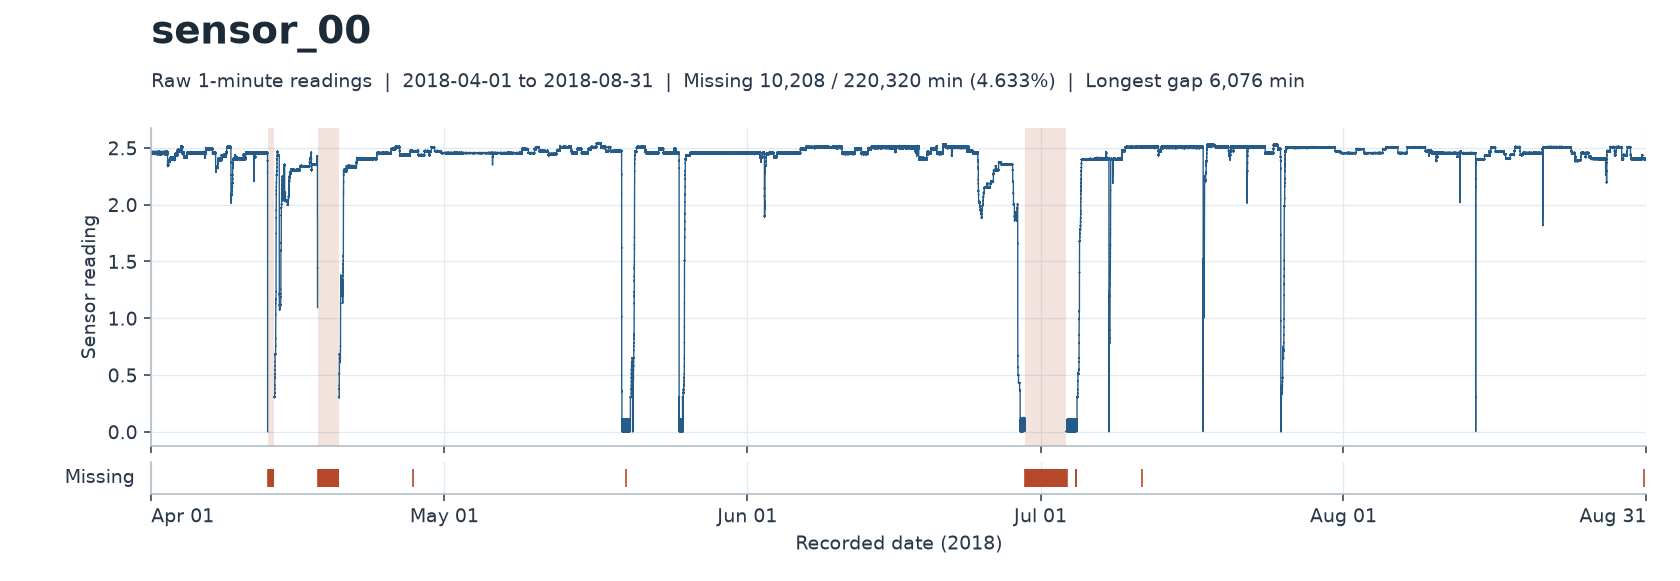

In [ ]:
from IPython.display import Image

output_dir = project_root / "figures/sensor_missingness"
output_dir.mkdir(parents=True, exist_ok=True)
with plt.rc_context({
    "font.size": 10,
    "axes.labelcolor": label_color,
    "xtick.color": label_color,
    "ytick.color": label_color,
    "axes.edgecolor": "#aebac6",
    "path.simplify": False,
    "agg.path.chunksize": 10000,
}):
    for sensor in sensor_columns:
        save_sensor_trace(trace_data[sensor], output_dir / f"{sensor}.png")

print(f"{len(sensor_columns)}개 PNG 저장: {output_dir.relative_to(project_root).as_posix()}/")
display(Image(filename=str(output_dir / f"{sensor_columns[0]}.png"), width=950))